### **Objective** : To Develop a predictive model using building energy data to estimate a building’s Energy Star score, and identify the key variables that most influence this score.

This is a supervised, regression machine learning task: given a set of data with targets (in this case the score) included, we want to train a model that can learn to map the features (also known as the explanatory variables) to the target.

1. Supervised problem: we are given both the features and the target
2. Regression problem: the target is a continous variable, in this case ranging from 0-100


Why this is Important:

    1. Promotes Energy Efficiency:
    Understanding which factors most impact Energy Star scores helps building managers prioritize energy-saving upgrades (e.g., better insulation, efficient HVAC systems).

    2. Informs Policy and Investment:
    Governments and investors can use this insight to incentivize or fund improvements in the most impactful areas—driving sustainable infrastructure decisions.

    3. Supports Benchmarking and Certification:
    Accurate predictions and variable insights enable quicker benchmarking, making it easier for buildings to qualify for green certifications and public recognition.

    4. Drives Operational Improvements:
    Facility teams can take targeted action—such as reducing energy use during peak hours or optimizing lighting—to boost scores and reduce costs.

    5. Enhances Predictive Maintenance:
    Variables linked with poor scores may also indicate failing systems (like chillers or boilers), allowing predictive maintenance and reducing downtime.

During training, we want the model to learn the relationship between the features and the score so we give it both the features and the answer. Then, to test how well the model has learned, we evaluate it on a testing set where it has never seen the answers!





Refer this link to understand about the data features : https://www.nyc.gov/html/gbee/downloads/misc/nyc_benchmarking_disclosure_data_definitions_2017.pdf

In [1]:
# Pandas and numpy for data manipulation
import pandas as pd
import numpy as np

# No warnings about setting value on copy of slice
pd.options.mode.chained_assignment = None

# Display up to 60 columns of a dataframe
pd.set_option('display.max_columns', 60)

# Matplotlib visualization
import matplotlib.pyplot as plt
%matplotlib inline

# Set default font size
plt.rcParams['font.size'] = 24

# Internal ipython tool for setting figure size
from IPython.core.pylabtools import figsize

# Seaborn for visualization
import seaborn as sns
sns.set(font_scale = 2)

# Splitting data into training and testing
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv(r'/content/Energy_star_building_data.csv')
df.head(2)

,Order,Property Id,Property Name,Parent Property Id,Parent Property Name,BBL - 10 digits,"NYC Borough, Block and Lot (BBL) self-reported",NYC Building Identification Number (BIN),Address 1 (self-reported),Address 2,Postal Code,Street Number,Street Name,Borough,DOF Gross Floor Area,Primary Property Type - Self Selected,List of All Property Use Types at Property,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),2nd Largest Property Use Type,2nd Largest Property Use - Gross Floor Area (ft²),3rd Largest Property Use Type,3rd Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Metered Areas (Energy),Metered Areas (Water),ENERGY STAR Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Fuel Oil #1 Use (kBtu),Fuel Oil #2 Use (kBtu),Fuel Oil #4 Use (kBtu),Fuel Oil #5 & 6 Use (kBtu),Diesel #2 Use (kBtu),District Steam Use (kBtu),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Release Date,Water Required?,DOF Benchmarking Submission Status,Latitude,Longitude,Community Board,Council District,Census Tract,NTA
0,1,13286,201/205,13286,201/205,1013160001,1013160001,1037549,201/205 East 42nd st.,Not Available,10017,675,3 AVENUE,Manhattan,289356.0,Office,Office,Office,293447,Not Available,Not Available,Not Available,Not Available,1963,2,100,Whole Building,Not Available,Not Available,305.6,303.1,37.8,Not Available,614.2,Not Available,Not Available,Not Available,Not Available,Not Available,5.15506751E7,Not Available,Not Available,38139374.2,1.10827705E7,6962.2,0,6962.2,762051,Not Available,Not Available,619.4,05/01/2017 05:32:03 PM,No,In Compliance,40.750791,-73.973963,6.0,4.0,88.0,Turtle Bay-East Midtown ...
1,2,28400,NYP Columbia (West Campus),28400,NYP Columbia (West Campus),1021380040,1-02138-0040,1084198; 1084387;1084385; 1084386; 1084388; 10...,622 168th Street,Not Available,10032,180,FT WASHINGTON AVENUE,Manhattan,3693539.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),3889181,Not Available,Not Available,Not Available,Not Available,1969,12,100,Whole Building,Whole Building,55,229.8,228.8,24.8,2.4,401.1,Not Available,1.96248472E7,Not Available,Not Available,Not Available,-3.914148026E8,933073441,9330734.4,332365924,9.62613121E7,55870.4,51016.4,4854.1,3889181,Not Available,Not Available,404.3,04/27/2017 11:23:27 AM,No,In Compliance,40.841402,-73.942568,12.0,10.0,251.0,Washington Heights South ...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11746 entries, 0 to 11745
Data columns (total 60 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   Order                                                       11746 non-null  int64  
 1   Property Id                                                 11746 non-null  int64  
 2   Property Name                                               11746 non-null  object 
 3   Parent Property Id                                          11746 non-null  object 
 4   Parent Property Name                                        11746 non-null  object 
 5   BBL - 10 digits                                             11735 non-null  object 
 6   NYC Borough, Block and Lot (BBL) self-reported              11746 non-null  object 
 7   NYC Building Identification Number (BIN)                    11746 non-null  object 
 

In [4]:
df.shape

(11746, 60)

In [5]:
# replace all occurence of Not Available with numpy's Not a Number (NaN)
df = df.replace({'Not Available': np.nan})

In [6]:
df.head(25)

,Order,Property Id,Property Name,Parent Property Id,Parent Property Name,BBL - 10 digits,"NYC Borough, Block and Lot (BBL) self-reported",NYC Building Identification Number (BIN),Address 1 (self-reported),Address 2,Postal Code,Street Number,Street Name,Borough,DOF Gross Floor Area,Primary Property Type - Self Selected,List of All Property Use Types at Property,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),2nd Largest Property Use Type,2nd Largest Property Use - Gross Floor Area (ft²),3rd Largest Property Use Type,3rd Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Metered Areas (Energy),Metered Areas (Water),ENERGY STAR Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Fuel Oil #1 Use (kBtu),Fuel Oil #2 Use (kBtu),Fuel Oil #4 Use (kBtu),Fuel Oil #5 & 6 Use (kBtu),Diesel #2 Use (kBtu),District Steam Use (kBtu),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Release Date,Water Required?,DOF Benchmarking Submission Status,Latitude,Longitude,Community Board,Council District,Census Tract,NTA
0,1,13286,201/205,13286,201/205,1013160001,1013160001,1037549,201/205 East 42nd st.,NaN,10017,675,3 AVENUE,Manhattan,289356.0,Office,Office,Office,293447,NaN,NaN,NaN,NaN,1963,2,100,Whole Building,NaN,NaN,305.6,303.1,37.8,NaN,614.2,NaN,NaN,NaN,NaN,NaN,5.15506751E7,NaN,NaN,38139374.2,1.10827705E7,6962.2,0,6962.2,762051,NaN,NaN,619.4,05/01/2017 05:32:03 PM,No,In Compliance,40.750791,-73.973963,6.0,4.0,88.0,Turtle Bay-East Midtown ...
1,2,28400,NYP Columbia (West Campus),28400,NYP Columbia (West Campus),1021380040,1-02138-0040,1084198; 1084387;1084385; 1084386; 1084388; 10...,622 168th Street,NaN,10032,180,FT WASHINGTON AVENUE,Manhattan,3693539.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),3889181,NaN,NaN,NaN,NaN,1969,12,100,Whole Building,Whole Building,55,229.8,228.8,24.8,2.4,401.1,NaN,1.96248472E7,NaN,NaN,NaN,-3.914148026E8,933073441,9330734.4,332365924,9.62613121E7,55870.4,51016.4,4854.1,3889181,NaN,NaN,404.3,04/27/2017 11:23:27 AM,No,In Compliance,40.841402,-73.942568,12.0,10.0,251.0,Washington Heights South ...
2,3,4778226,MSCHoNY North,28400,NYP Columbia (West Campus),1021380030,1-02138-0030,1063380,3975 Broadway,NaN,10032,3975,BROADWAY,Manhattan,152765.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),231342,NaN,NaN,NaN,NaN,1924,1,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,231342,NaN,NaN,NaN,04/27/2017 11:23:27 AM,No,In Compliance,40.840427,-73.940249,12.0,10.0,251.0,Washington Heights South ...
3,4,4778267,Herbert Irving Pavilion & Millstein Hospital,28400,NYP Columbia (West Campus),1021390001,1-02139-0001,1087281; 1076746,161 Fort Washington Ave,177 Fort Washington Ave,10032,161,FT WASHINGTON AVENUE,Manhattan,891040.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),1305748,NaN,NaN,NaN,NaN,1971,1,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,1305748,NaN,NaN,NaN,04/27/2017 11:23:27 AM,No,In Compliance,40.840746,-73.942854,12.0,10.0,255.0,Washington Heights South ...
4,5,4778288,Neuro Institute,28400,NYP Columbia (West Campus),1021390085,1-02139-0085,1063403,710 West 168th Street,NaN,10032,193,FT WASHINGTON AVENUE,Manhattan,211400.0,Hospital (General Med

In [7]:
# lets make a copy of this data and work on that only

data = pd.DataFrame.copy(df)

In [8]:
data.tail(10)

,Order,Property Id,Property Name,Parent Property Id,Parent Property Name,BBL - 10 digits,"NYC Borough, Block and Lot (BBL) self-reported",NYC Building Identification Number (BIN),Address 1 (self-reported),Address 2,Postal Code,Street Number,Street Name,Borough,DOF Gross Floor Area,Primary Property Type - Self Selected,List of All Property Use Types at Property,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),2nd Largest Property Use Type,2nd Largest Property Use - Gross Floor Area (ft²),3rd Largest Property Use Type,3rd Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Metered Areas (Energy),Metered Areas (Water),ENERGY STAR Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Fuel Oil #1 Use (kBtu),Fuel Oil #2 Use (kBtu),Fuel Oil #4 Use (kBtu),Fuel Oil #5 & 6 Use (kBtu),Diesel #2 Use (kBtu),District Steam Use (kBtu),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Release Date,Water Required?,DOF Benchmarking Submission Status,Latitude,Longitude,Community Board,Council District,Census Tract,NTA
11736,14983,4950741,ROSENBERG: 1955 Grand Concourse,Not Applicable: Standalone Property,Not Applicable: Standalone Property,2028080051,2-02808-0051\t,2007688,1955 Grand Concourse,NaN,10461,1955,GRAND CONCOURSE,Bronx,59800.0,Multifamily Housing,Multifamily Housing,Multifamily Housing,67350,NaN,NaN,NaN,NaN,1930,1,100,Whole Building,NaN,83,102,106.5,4.6,0.9,144.2,NaN,277173,NaN,NaN,NaN,NaN,5511800.5,58436.7,1081157,307746.1,413.7,313.3,100.3,67350,8862,131.58,140.5,04/26/2017 04:59:11 PM,Yes,NaN,40.850655,-73.905048,5.0,14.0,23501.0,Mount Hope ...
11737,14984,4950728,ROSENBERG: 1480 Popham Ave,Not Applicable: Standalone Property,Not Applicable: Standalone Property,2028770211,2-02877-0211\t,2008874,1480 Popham Ave,NaN,10461,1480,POPHAM AVENUE,Bronx,60480.0,Multifamily Housing,Multifamily Housing,Multifamily Housing,72372,NaN,NaN,NaN,NaN,1940,1,100,Whole Building,NaN,83,95,101.4,5,0.8,142.2,NaN,NaN,NaN,NaN,NaN,NaN,5593400.1,60973.7,1284867.1,363247.5,416.3,297.1,119.2,72372,7215.4,99.7,136.9,04/26/2017 04:59:11 PM,No,NaN,40.847884,-73.921891,5.0,14.0,20501.0,University Heights-Morris Heights ...
11738,14985,4408791,Milton Gordon: 679 WEST 239 STREET,Not Applicable: Standalone Property,Not Applicable: Standalone Property,2059200510,2-05920-0510\t,2085873,679 WEST 239 STREET,NaN,10463,679,WEST 239 STREET,Bronx,125526.0,Multifamily Housing,Multifamily Housing,Multifamily Housing,131802,NaN,NaN,NaN,NaN,1960,1,100,Whole Building,NaN,100,12.2,11.8,2.8,0,32.5,NaN,NaN,NaN,NaN,NaN,NaN,291600,2973.4,1315977.7,370162,137.6,15.5,122.1,131802,2989.6,22.68,33.7,05/01/2017 01:22:10 PM,No,NaN,40.889859,-73.914254,8.0,11.0,309.0,North Riverdale-Fieldston-Riverdale ...
11739,14986,4408781,Milton Gordon: 699 WEST 239 STREET,Not Applicable: Standalone Property,Not Applicable: Standalone Property,2059200687,2-05920-0687\t,2085876,699 WEST 239 STREET,NaN,10463,699,WEST 239 STREET,Bronx,162000.0,Multifamily Housing,Multifamily Housing,Multifamily Housing,170100,NaN,NaN,NaN,NaN,1962,1,100,Whole Building,Whole Building,99,75,82.5,NaN,0.8,86.6,NaN,NaN,NaN,NaN,NaN,NaN,1.27625995E7,140257.4,NaN,NaN,677.9,677.9,0,170100,NaN,NaN,78.8,04/26/2017 04:32:19 PM,NaN,NaN,40.889914,-73.914963,8.0,11.0,309.0,North Riverdale-Fieldston-Riverdale ...
11740,14987,4940405,Advanced: 161 Henry Street,Not Applicable: Standalone Property,Not Applicable: Standalone Property,3002370

In [9]:
# Convert columns to float, coercing any unparseable string values to NaN
for col in list(data.columns):
    if ('ft²' in col or 'kBtu' in col or 'Metric Tons CO2e' in col or 'kWh' in col or 'therms' in col or 'gal' in col or 'Score' in col):
        data[col] = pd.to_numeric(data[col], errors='coerce')

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11746 entries, 0 to 11745
Data columns (total 60 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   Order                                                       11746 non-null  int64  
 1   Property Id                                                 11746 non-null  int64  
 2   Property Name                                               11746 non-null  object 
 3   Parent Property Id                                          11746 non-null  object 
 4   Parent Property Name                                        11746 non-null  object 
 5   BBL - 10 digits                                             11735 non-null  object 
 6   NYC Borough, Block and Lot (BBL) self-reported              11735 non-null  object 
 7   NYC Building Identification Number (BIN)                    11584 non-null  object 
 

In [11]:
data.describe()

,Order,Property Id,DOF Gross Floor Area,Largest Property Use Type - Gross Floor Area (ft²),2nd Largest Property Use - Gross Floor Area (ft²),3rd Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,ENERGY STAR Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Fuel Oil #1 Use (kBtu),Fuel Oil #2 Use (kBtu),Fuel Oil #4 Use (kBtu),Fuel Oil #5 & 6 Use (kBtu),Diesel #2 Use (kBtu),District Steam Use (kBtu),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Latitude,Longitude,Community Board,Council District,Census Tract
count,11746.000000,1.174600e+04,1.162800e+04,1.174400e+04,3741.000000,1484.000000,11746.000000,11746.000000,11746.000000,9642.000000,11583.000000,10281.000000,10959.000000,9783.000000,10281.000000,9.000000e+00,2.581000e+03,1.321000e+03,5.940000e+02,1.600000e+01,9.360000e+02,1.030400e+04,9.784000e+03,1.150200e+04,1.096000e+04,1.167200e+04,1.166300e+04,1.168100e+04,1.174600e+04,7.762000e+03,7762.000000,11583.000000,9483.000000,9483.000000,9483.000000,9483.000000,9483.000000
mean,7185.759578,3.642958e+06,1.732695e+05,1.605524e+05,22778.682010,12016.825270,1948.738379,1.289971,98.762557,59.854594,280.071484,309.747466,11.072643,1.901441,417.915709,3.395398e+06,3.186882e+06,5.294367e+06,2.429105e+06,1.193594e+06,2.868907e+08,5.048545e+07,5.364578e+05,5.965472e+06,1.768752e+06,4.553657e+03,2.477937e+03,2.076339e+03,1.673739e+05,1.591798e+04,136.172432,385.908029,40.754379,-73.957057,7.140673,15.771275,4977.596647
std,4323.859984,1.049070e+06,3.367055e+05,3.095746e+05,55094.441422,27959.755486,30.576386,4.017484,7.501603,29.993586,8607.178877,9784.731207,127.733868,97.204587,10530.524339,2.213237e+06,5.497154e+06,5.881863e+06,4.442946e+06,3.558178e+06,3.124603e+09,3.914719e+09,4.022606e+07,3.154430e+07,9.389154e+06,2.041639e+05,1.954498e+05,5.931295e+04,3.189238e+05,1.529524e+05,1730.726938,9312.736225,0.080120,0.046337,3.954129,15.674375,13520.422990
min,1.000000,7.365000e+03,5.002800e+04,5.400000e+01,0.000000,0.000000,1600.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.085973e+05,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-4.690797e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-2.313430e+04,0.000000e+00,0.000000e+00,0.000000,0.000000,40.516065,-74.243582,1.000000,1.000000,1.000000
25%,3428.250000,2.747222e+06,6.524000e+04,6.520100e+04,4000.000000,1720.750000,1927.000000,1.000000,100.000000,37.000000,61.800000,65.100000,3.800000,0.100000,103.500000,1.663594e+06,2.550378e+05,2.128213e+06,0.000000e+00,5.698020e+04,4.320254e+06,1.098251e+06,1.176952e+04,1.043673e+06,3.019975e+05,3.287000e+02,1.474500e+02,9.480000e+01,6.699400e+04,2.595400e+03,27.150000,99.400000,40.707226,-73.984662,4.000000,4.000000,100.000000
50%,6986.500000,3.236404e+06,9.313850e+04,9.132400e+04,8654.000000,5000.000000,1941.000000,1.000000,100.000000,65.000000,78.500000,82.500000,5.300000,0.500000,129.400000,4.328815e+06,1.380138e+06,4.312984e+06,0.000000e+00,2.070020e+05,9.931240e+06,4.103962e+06,4.445525e+04,1.855196e+06,5.416312e+05,5.002500e+02,2.726000e+02,1.718000e+02,9.408000e+04,4.692500e+03,45.095000,124.900000,40.759130,-73.962810,7.000000,9.000000,201.000000
75%,11054.500000,4.409092e+06,1.596140e+05,1.532550e+05,20000.000000,12000.000000,1966.000000,1.000000,100.000000,85.000000,97.600000,102.500000,9.200000,0.700000,167.200000,4.938947e+06,4.445808e+06,6.514520e+06,4.293825e+06,2.918332e+0

In [12]:
def missing_val_table(data):
    mis_val = data.isnull().sum()
    mis_val_percent = 100 * data.isnull().sum() / len(data)

    # put it in a table
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)

    # put names to the columns
    mis_val_table_ren_columns = mis_val_table.rename(columns = {0 : 'Missing Values', 1: '% of Total Values'})

    # sort the table by percentage of missing percentage in descending order
    mis_val_table_ren_columns = mis_val_table_ren_columns[mis_val_table_ren_columns.iloc[:,1] != 0].sort_values('% of Total Values', ascending=False).round(1)

    # print the information
    print ("Your selected dataframe has " + str(data.shape[1]) + " columns.\n" "There are " + str(mis_val_table_ren_columns.shape[0]) + " columns that have missing values.")

    return mis_val_table_ren_columns

missing_val_table(data)

Your selected dataframe has 60 columns.
There are 46 columns that have missing values.


,Missing Values,% of Total Values
Fuel Oil #1 Use (kBtu),11737,99.9
Diesel #2 Use (kBtu),11730,99.9
Address 2,11539,98.2
Fuel Oil #5 & 6 Use (kBtu),11152,94.9
District Steam Use (kBtu),10810,92.0
Fuel Oil #4 Use (kBtu),10425,88.8
3rd Largest Property Use Type - Gross Floor Area (ft²),10262,87.4
3rd Largest Property Use Type,10262,87.4
Fuel Oil #2 Use (kBtu),9165,78.0
2nd Largest Property Use Type,8005,68.2


If a columns has very high percentage of misisng data its prudent to drop such columns.

We will remove any columns that has more than 50% data missing

In [13]:
# remove columns where we have more than 50% data missing

missing_df = missing_val_table(data)
missing_columns = list(missing_df[missing_df['% of Total Values'] > 50].index)
print("We will remove %d columns" % len(missing_columns))
data = data.drop(columns = missing_columns)

Your selected dataframe has 60 columns.
There are 46 columns that have missing values.
We will remove 11 columns


In [14]:
data.head(25)

,Order,Property Id,Property Name,Parent Property Id,Parent Property Name,BBL - 10 digits,"NYC Borough, Block and Lot (BBL) self-reported",NYC Building Identification Number (BIN),Address 1 (self-reported),Postal Code,Street Number,Street Name,Borough,DOF Gross Floor Area,Primary Property Type - Self Selected,List of All Property Use Types at Property,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Metered Areas (Energy),Metered Areas (Water),ENERGY STAR Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Release Date,Water Required?,DOF Benchmarking Submission Status,Latitude,Longitude,Community Board,Council District,Census Tract,NTA
0,1,13286,201/205,13286,201/205,1013160001,1013160001,1037549,201/205 East 42nd st.,10017,675,3 AVENUE,Manhattan,289356.0,Office,Office,Office,293447.0,1963,2,100,Whole Building,NaN,NaN,305.6,303.1,37.8,NaN,614.2,NaN,NaN,38139374.2,11082770.5,6962.2,0.0,6962.2,762051,NaN,NaN,619.4,05/01/2017 05:32:03 PM,No,In Compliance,40.750791,-73.973963,6.0,4.0,88.0,Turtle Bay-East Midtown ...
1,2,28400,NYP Columbia (West Campus),28400,NYP Columbia (West Campus),1021380040,1-02138-0040,1084198; 1084387;1084385; 1084386; 1084388; 10...,622 168th Street,10032,180,FT WASHINGTON AVENUE,Manhattan,3693539.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),3889181.0,1969,12,100,Whole Building,Whole Building,55.0,229.8,228.8,24.8,2.4,401.1,9.330734e+08,9.330734e+06,332365924.0,96261312.1,55870.4,51016.4,4854.1,3889181,NaN,NaN,404.3,04/27/2017 11:23:27 AM,No,In Compliance,40.841402,-73.942568,12.0,10.0,251.0,Washington Heights South ...
2,3,4778226,MSCHoNY North,28400,NYP Columbia (West Campus),1021380030,1-02138-0030,1063380,3975 Broadway,10032,3975,BROADWAY,Manhattan,152765.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),231342.0,1924,1,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,231342,NaN,NaN,NaN,04/27/2017 11:23:27 AM,No,In Compliance,40.840427,-73.940249,12.0,10.0,251.0,Washington Heights South ...
3,4,4778267,Herbert Irving Pavilion & Millstein Hospital,28400,NYP Columbia (West Campus),1021390001,1-02139-0001,1087281; 1076746,161 Fort Washington Ave,10032,161,FT WASHINGTON AVENUE,Manhattan,891040.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),1305748.0,1971,1,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1305748,NaN,NaN,NaN,04/27/2017 11:23:27 AM,No,In Compliance,40.840746,-73.942854,12.0,10.0,255.0,Washington Heights South ...
4,5,4778288,Neuro Institute,28400,NYP Columbia (West Campus),1021390085,1-02139-0085,1063403,710 West 168th Street,10032,193,FT WASHINGTON AVENUE,Manhattan,211400.0,Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),Hospital (General Medical & Surgical),179694.0,1932,1,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,179694,NaN,NaN,NaN,04/27/2017 11:23:27 AM,No,In Compliance,40.841559,-73.942528,12.0,10.0,255.0,Washington Heights South ...
5,6,28402,NYP Cornell (East Campus),28402,NYP Cornell (East Campus),1014800001,1-01480-0001,1084781; 1084780,525 East 68th Street,10021,1176,YORK AVENUE,Manhattan,2230742.0,Hospital (General Medical & Surgical),Hospital (

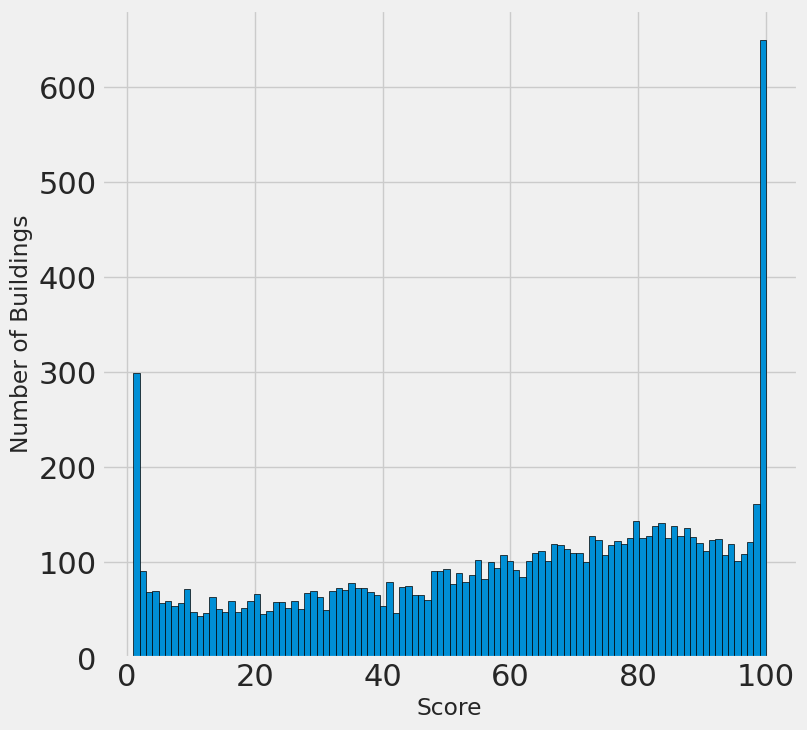

In [15]:
# Visualize the data
# lets start with univariate analysis

figsize(8,8)

data = data.rename(columns = {'ENERGY STAR Score': 'Score'})

plt.style.use('fivethirtyeight')
plt.hist(data['Score'].dropna(), bins=100, edgecolor='black')
plt.xlabel('Score')
plt.ylabel('Number of Buildings')
plt.show()

As we see a very high number of buiding score around 0 and 100. Due to self reporting we understand like lot of buiding managers would report high values. But it makes less sense why large number of them are reporting value as 0.

Lets look at other features to understand what might be going on

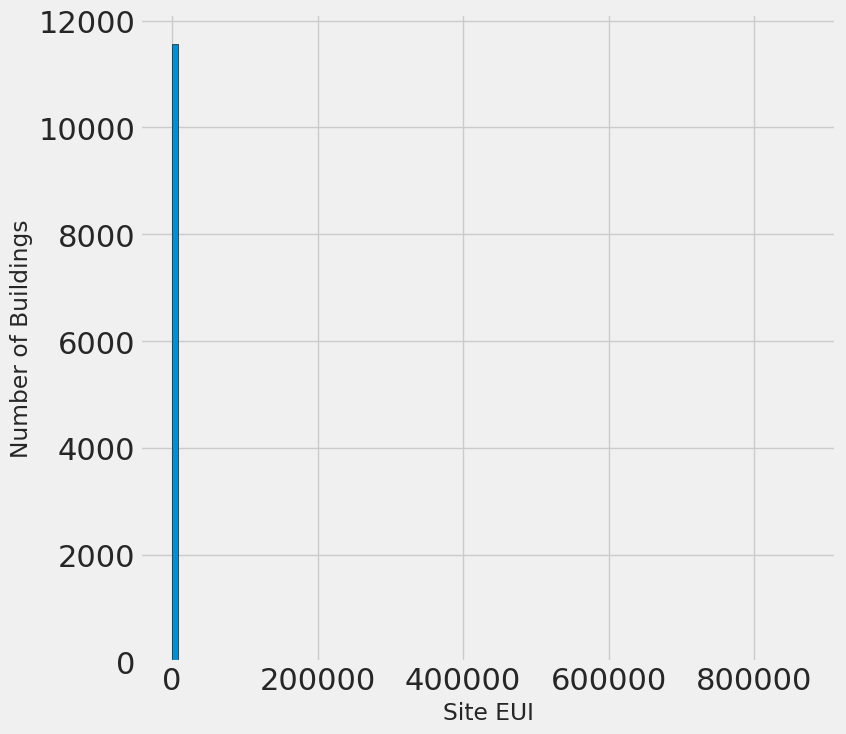

In [16]:
plt.hist(data['Site EUI (kBtu/ft²)'].dropna(), bins = 100, edgecolor='k')
plt.xlabel('Site EUI')
plt.ylabel('Number of Buildings')
plt.show()

In [17]:
data['Site EUI (kBtu/ft²)'].describe()

,Site EUI (kBtu/ft²)
count,11583.000000
mean,280.071484
std,8607.178877
min,0.000000
25%,61.800000
50%,78.500000
75%,97.600000
max,869265.000000


In [18]:
data['Site EUI (kBtu/ft²)'].dropna().sort_values().tail(20)

,Site EUI (kBtu/ft²)
1276,19313.5
3163,22259.0
1595,24541.2
6885,25789.4
2155,26451.7
3265,28373.6
847,34326.8
3373,49340.7
3139,50621.6
2262,50823.6


In [19]:
data.loc[data['Site EUI (kBtu/ft²)'] == 869265.0, :]
#

,Order,Property Id,Property Name,Parent Property Id,Parent Property Name,BBL - 10 digits,"NYC Borough, Block and Lot (BBL) self-reported",NYC Building Identification Number (BIN),Address 1 (self-reported),Postal Code,Street Number,Street Name,Borough,DOF Gross Floor Area,Primary Property Type - Self Selected,List of All Property Use Types at Property,Largest Property Use Type,Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Metered Areas (Energy),Metered Areas (Water),Score,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Weather Normalized Source EUI (kBtu/ft²),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Total GHG Emissions (Metric Tons CO2e),Direct GHG Emissions (Metric Tons CO2e),Indirect GHG Emissions (Metric Tons CO2e),Property GFA - Self-Reported (ft²),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Source EUI (kBtu/ft²),Release Date,Water Required?,DOF Benchmarking Submission Status,Latitude,Longitude,Community Board,Council District,Census Tract,NTA
8068,9984,4414323,234 Skillman,Not Applicable: Standalone Property,Not Applicable: Standalone Property,3028937502,3028937502,"3390250 , 3338313",234 Skillman avenue,11211,234,SKILLMAN AVENUE,Brooklyn,61811.0,Multifamily Housing,Multifamily Housing,Multifamily Housing,56900.0,2004,1,90,Whole Building,NaN,1.0,869265.0,939329.0,9.9,9393.0,986366.0,4.945919e+10,534458968.8,1983655.6,563239.6,2627199.1,2627015.0,184.1,56900,2547.9,44.78,912801.1,05/01/2017 11:34:14 PM,NaN,In Compliance,40.716233,-73.94141,1.0,34.0,477.0,East Williamsburg ...


In [20]:
# Outlier removal

# lets use IQR technique to remove extreme values

first_quartile = data['Site EUI (kBtu/ft²)'].dropna().quantile(0.25)
third_quartile = data['Site EUI (kBtu/ft²)'].dropna().quantile(0.75)
iqr = third_quartile - first_quartile

data = data[(data['Site EUI (kBtu/ft²)']> (first_quartile - 3*iqr)) &
            (data['Site EUI (kBtu/ft²)']<(third_quartile + 3*iqr))]

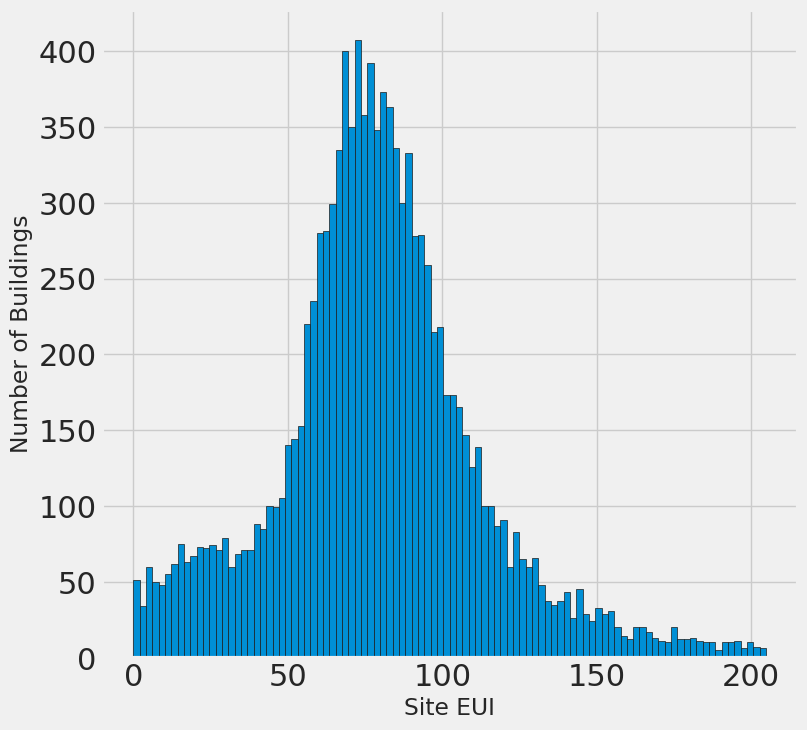

In [21]:
plt.hist(data['Site EUI (kBtu/ft²)'].dropna(), bins = 100, edgecolor='k')
plt.xlabel('Site EUI')
plt.ylabel('Number of Buildings')
plt.show()

In [22]:
# lets look for relations between columns and outputs

types_building = data.dropna(subset=['Score'])
types_building = types_building["Largest Property Use Type"].value_counts()
types_building = list(types_building[types_building.values > 80].index)
types_building

['Multifamily Housing',
 'Office',
 'Hotel',
 'Non-Refrigerated Warehouse',
 'K-12 School',
 'Residence Hall/Dormitory',
 'Senior Care Community']

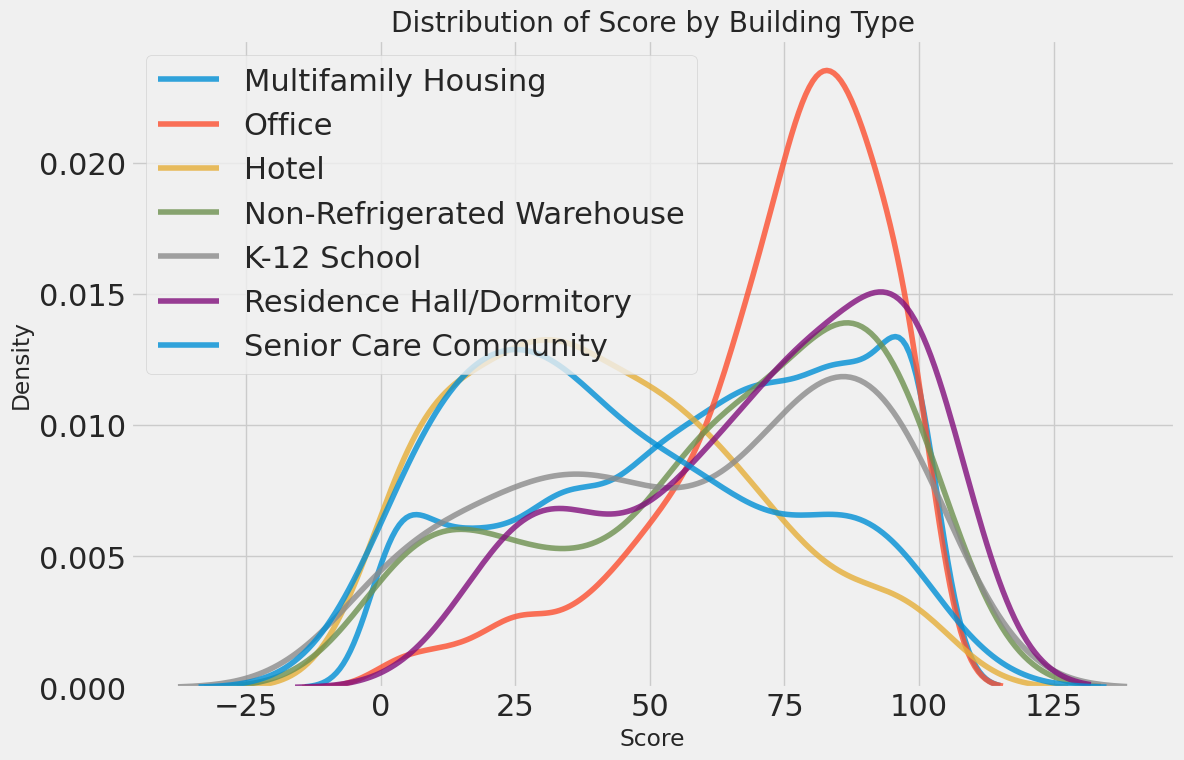

In [23]:
# plot these distributions with scores

figsize(12,8)
for types in types_building:
    subset = data[data["Largest Property Use Type"]==types]

    sns.kdeplot(subset['Score'].dropna(), label = types, alpha = 0.8)

plt.xlabel('Score')
plt.ylabel('Density')
plt.title('Distribution of Score by Building Type')
plt.legend()
plt.show()

In [24]:
# create a list of boroughs with more than 100 observations

boroughs = data.dropna(subset=['Score'])
boroughs = boroughs["Borough"].value_counts()
boroughs = list(boroughs[boroughs.values > 100]. index)
boroughs

['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']

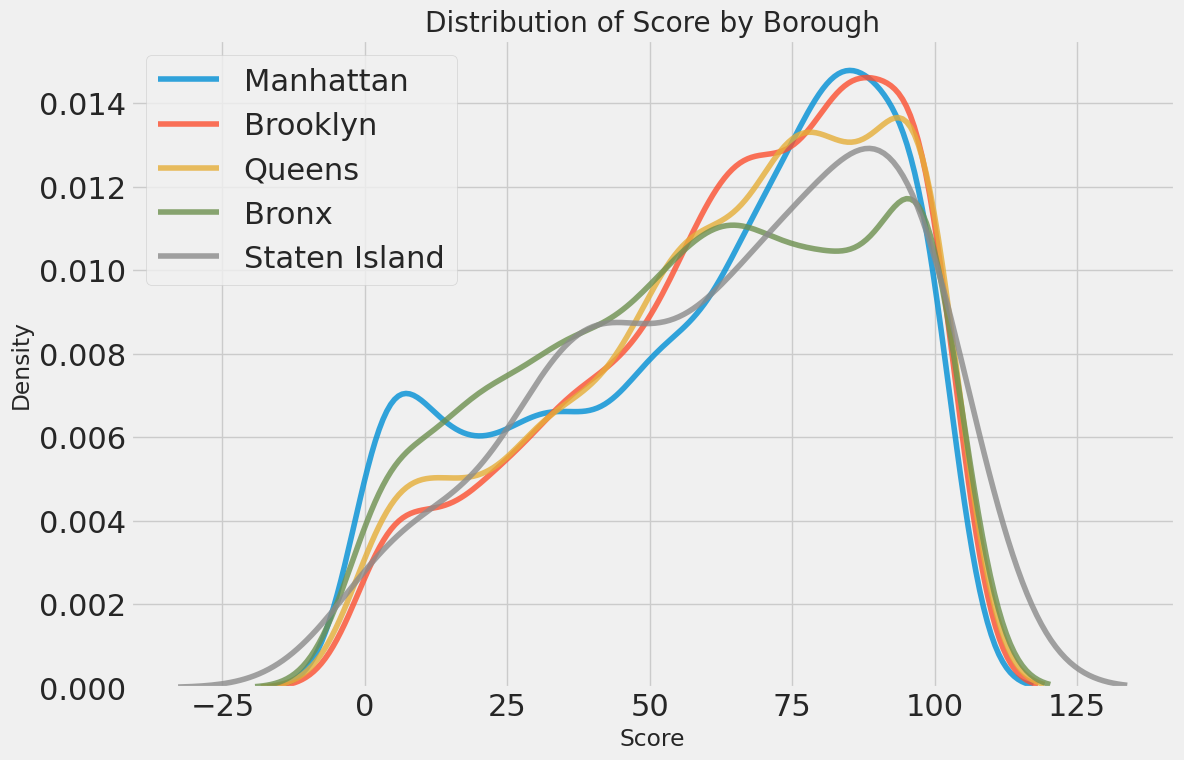

In [25]:
# plot energy score against each borough

for borough in boroughs:
    subset = data[data["Borough"]==borough]

    sns.kdeplot(subset['Score'].dropna(), label = borough, alpha = 0.8)

plt.xlabel('Score')
plt.ylabel('Density')
plt.title('Distribution of Score by Borough')
plt.legend()
plt.show()

In [26]:
# correlation of data fetaures (numeric) to target

corr_data = data.corr(numeric_only=True)['Score'].sort_values()
print(corr_data)

Site EUI (kBtu/ft²)                                          -0.723864
Weather Normalized Site EUI (kBtu/ft²)                       -0.713993
Weather Normalized Source EUI (kBtu/ft²)                     -0.645542
Source EUI (kBtu/ft²)                                        -0.641037
Weather Normalized Site Electricity Intensity (kWh/ft²)      -0.358394
Weather Normalized Site Natural Gas Intensity (therms/ft²)   -0.346046
Direct GHG Emissions (Metric Tons CO2e)                      -0.147792
Weather Normalized Site Natural Gas Use (therms)             -0.135211
Natural Gas Use (kBtu)                                       -0.133648
Year Built                                                   -0.121249
Total GHG Emissions (Metric Tons CO2e)                       -0.113136
Electricity Use - Grid Purchase (kBtu)                       -0.050639
Weather Normalized Site Electricity (kWh)                    -0.048207
Latitude                                                     -0.048196
Proper

In [27]:
# correlation only captures linear relationships

# Lets figure out if there are some non -linear relationshsips as well well which are powerful

numeric_subset = data.select_dtypes(include=[np.number])
for col in numeric_subset.columns:
    if col == 'Score':
        next
    else :
        numeric_subset['Log_' + col] = np.log(numeric_subset[col])
        numeric_subset['sqrt_' + col] = np.sqrt(numeric_subset[col])

catergorial_subset = data[['Borough', 'Largest Property Use Type']]

# convert categorical value to encode one hot encoding

categorical_subset = pd.get_dummies(catergorial_subset)

data_final = pd.concat([numeric_subset, categorical_subset], axis = 1)
data_final = data_final.dropna(subset=['Score'])

data_correlation = data_final.corr()['Score'].sort_values()
print(data_correlation)



/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = geta

Site EUI (kBtu/ft²)                                             -0.723864
Weather Normalized Site EUI (kBtu/ft²)                          -0.713993
sqrt_Site EUI (kBtu/ft²)                                        -0.699817
sqrt_Weather Normalized Site EUI (kBtu/ft²)                     -0.689019
sqrt_Weather Normalized Source EUI (kBtu/ft²)                   -0.671044
                                                                   ...   
Largest Property Use Type_Restaurant                                  NaN
Largest Property Use Type_Self-Storage Facility                       NaN
Largest Property Use Type_Social/Meeting Hall                         NaN
Largest Property Use Type_Strip Mall                                  NaN
Largest Property Use Type_Urgent Care/Clinic/Other Outpatient         NaN
Name: Score, Length: 138, dtype: float64


In [28]:
data_correlation.head(30)

,Score
Site EUI (kBtu/ft²),-0.723864
Weather Normalized Site EUI (kBtu/ft²),-0.713993
sqrt_Site EUI (kBtu/ft²),-0.699817
sqrt_Weather Normalized Site EUI (kBtu/ft²),-0.689019
sqrt_Weather Normalized Source EUI (kBtu/ft²),-0.671044
sqrt_Source EUI (kBtu/ft²),-0.669396
Weather Normalized Source EUI (kBtu/ft²),-0.645542
Source EUI (kBtu/ft²),-0.641037
Log_Source EUI (kBtu/ft²),-0.622892
Log_Weather Normalized Source EUI (kBtu/ft²),-0.620329


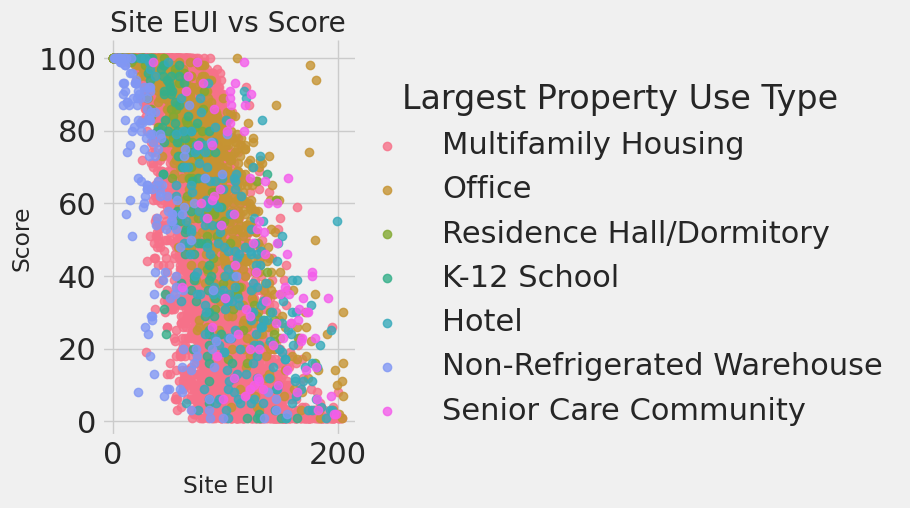

In [29]:
# two variable plot

figsize(12,6)

data_final["Largest Property Use Type"] = data.dropna(subset=['Score'])["Largest Property Use Type"]

data_final = data_final[data_final["Largest Property Use Type"].isin(types_building)]
sns.lmplot(x="Site EUI (kBtu/ft²)", y = "Score", data = data_final, fit_reg=False, hue = "Largest Property Use Type")
plt.xlabel('Site EUI')
plt.ylabel('Score')
plt.title('Site EUI vs Score')
plt.show()

In [30]:
# Lets look at only those features which are powerful in correlation

plot_data = data_final[['Score', 'Site EUI (kBtu/ft²)', 'Weather Normalized Site EUI (kBtu/ft²)', 'Log_Total GHG Emissions (Metric Tons CO2e)' ]]

# replace the inf with nan

plot_data = plot_data.replace({np.inf: np.nan, -np.inf: np.nan})

# rename columns

plot_data = plot_data.rename(columns = {'Site EUI (kBtu/ft²)':"Site EUI",
                                        'Weather Normalized Site EUI kBtu/ft²)':"Weather Normalized Site EUI",
                                        'log Total GHG Emissions (Metric Tons CO2e)':"log Total GHG Emissions"})

# drop missing values

plot_data = plot_data.dropna()

print (plot_data)

       Score  Site EUI  Weather Normalized Site EUI (kBtu/ft²)  \
18      72.0      76.2                                    79.9   
19      67.0      75.7                                    79.0   
20      80.0      77.1                                    82.7   
22     100.0      23.7                                    23.4   
23     100.0      17.9                                    17.4   
...      ...       ...                                     ...   
11741   98.0      81.4                                    87.0   
11742   16.0     109.3                                   117.7   
11743   83.0      44.3                                    43.9   
11744   92.0      70.0                                    74.9   
11745   19.0     130.2                                   140.5   

       Log_Total GHG Emissions (Metric Tons CO2e)  
18                                       7.546129  
19                                       7.093737  
20                                       6.535241  

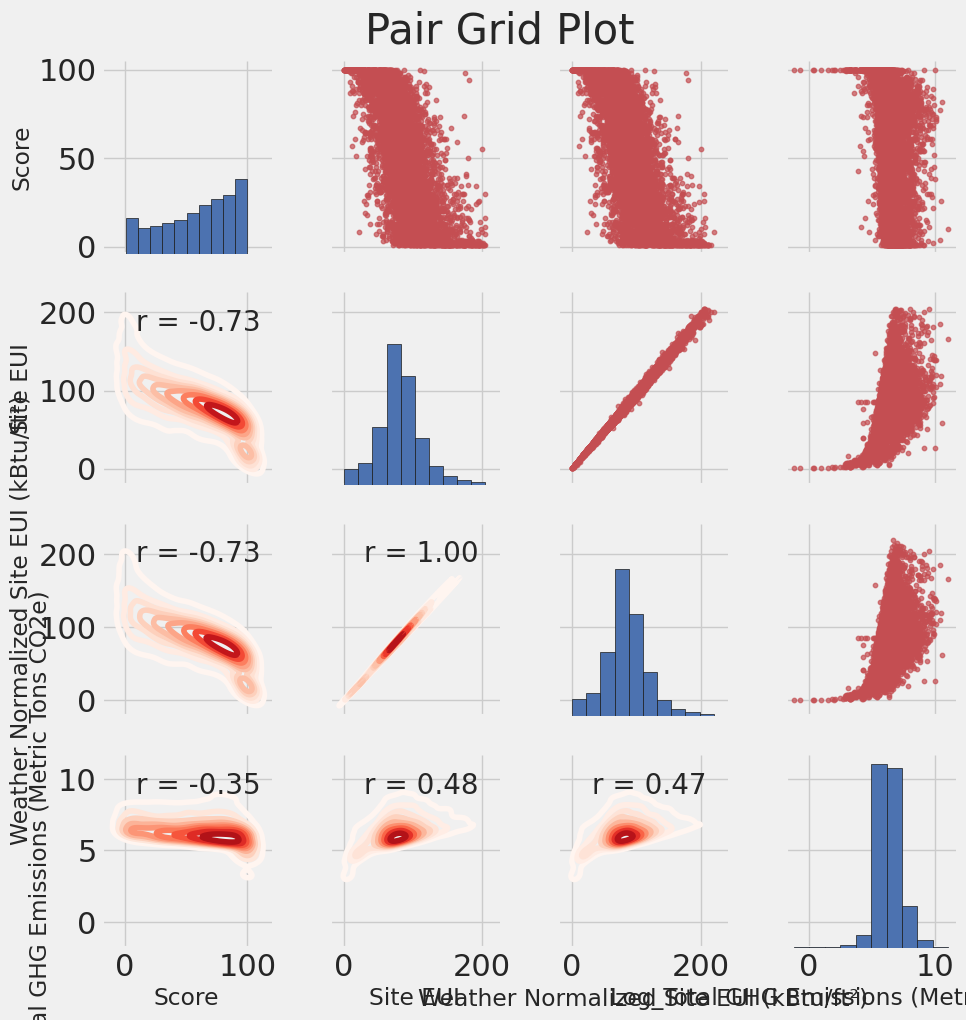

In [31]:
def corr_func(x, y, **kwargs):
    r = np.corrcoef(x,y)[0][1]
    ax = plt.gca()
    ax.annotate("r = {:.2f}".format(r),
                xy=(.2, .8), xycoords=ax.transAxes,
                size = 20)

# create a pair grid

grid = sns.PairGrid(data = plot_data)

# upper half should be scatter plot
grid.map_upper(plt.scatter, color = 'r', s = 10, linewidth = 1, alpha = 0.7)

# diagonal grids should be histogram
grid.map_diag(plt.hist, color = 'b', edgecolor = 'k')

# lower half should be correlation and density plot
grid.map_lower(corr_func)
grid.map_lower(sns.kdeplot, cmap = 'Reds')

plt.suptitle('Pair Grid Plot', size = 30, y = 1.02)
plt.show()

In [32]:
# Feature engineering

# check for multicollinaerity

features = data.copy()

# select numeric subset columns

numeric_subset = data.select_dtypes(include=[np.number])

# create columns with log of numeric columns
for col in numeric_subset.columns:
    if col == 'Score':
        next
    else :
        numeric_subset['Log_' + col] = np.log(numeric_subset[col])

categorical_subset = data[['Borough', 'Largest Property Use Type']]

# convert categorical value to encode one hot encoding

categorical_subset = pd.get_dummies(categorical_subset)
features = pd.concat([numeric_subset, categorical_subset], axis = 1)

features.shape

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = geta

(11319, 110)

In [33]:
# drop multicollinear features
def remove_colliear_features(x,threshold):

    y = x['Score']
    x = x.drop(columns = ['Score'])

    #calculate correlation

    corr_matrix = x.corr()
    iters = range(len(corr_matrix.columns)-1)
    drop_cols = []

    # iterate through the correlation matrix and compare correlations
    for i in iters:
        for j in range(i):
            item = corr_matrix.iloc[j:(j+1), (i+1):(i+2)]
            col = item.columns
            row = item.index
            val = abs(item.values)

            # if the correlation exceeds the therhold value we should drop the columns

            if val >= threshold:
                drop_cols.append(col.values[0])

    # drop the columns
    drops = set(drop_cols)
    x = x.drop(columns = drops)

    x['Score'] = y
    return x

In [34]:
features = remove_colliear_features(features, 0.75)


In [35]:
features = features.dropna(axis = 1, how ='all')
features

,Order,Property Id,DOF Gross Floor Area,Largest Property Use Type - Gross Floor Area (ft²),Year Built,Number of Buildings - Self-reported,Occupancy,Site EUI (kBtu/ft²),Weather Normalized Site EUI (kBtu/ft²),Weather Normalized Site Electricity Intensity (kWh/ft²),Weather Normalized Site Natural Gas Intensity (therms/ft²),Natural Gas Use (kBtu),Weather Normalized Site Natural Gas Use (therms),Electricity Use - Grid Purchase (kBtu),Weather Normalized Site Electricity (kWh),Water Use (All Water Sources) (kgal),Water Intensity (All Water Sources) (gal/ft²),Latitude,Longitude,Community Board,Census Tract,Log_DOF Gross Floor Area,Log_Largest Property Use Type - Gross Floor Area (ft²),Log_Number of Buildings - Self-reported,Log_Natural Gas Use (kBtu),Log_Weather Normalized Site Natural Gas Use (therms),Log_Direct GHG Emissions (Metric Tons CO2e),Log_Water Use (All Water Sources) (kgal),Log_Water Intensity (All Water Sources) (gal/ft²),Borough_Bronx,...,Largest Property Use Type_Non-Refrigerated Warehouse,Largest Property Use Type_Office,Largest Property Use Type_Other,Largest Property Use Type_Other - Education,Largest Property Use Type_Other - Entertainment/Public Assembly,Largest Property Use Type_Other - Lodging/Residential,Largest Property Use Type_Other - Mall,Largest Property Use Type_Other - Public Services,Largest Property Use Type_Other - Recreation,Largest Property Use Type_Other - Services,Largest Property Use Type_Other - Specialty Hospital,Largest Property Use Type_Outpatient Rehabilitation/Physical Therapy,Largest Property Use Type_Parking,Largest Property Use Type_Performing Arts,Largest Property Use Type_Pre-school/Daycare,Largest Property Use Type_Refrigerated Warehouse,"Largest Property Use Type_Repair Services (Vehicle, Shoe, Locksmith, etc.)",Largest Property Use Type_Residence Hall/Dormitory,Largest Property Use Type_Residential Care Facility,Largest Property Use Type_Restaurant,Largest Property Use Type_Retail Store,Largest Property Use Type_Self-Storage Facility,Largest Property Use Type_Senior Care Community,Largest Property Use Type_Social/Meeting Hall,Largest Property Use Type_Strip Mall,Largest Property Use Type_Supermarket/Grocery Store,Largest Property Use Type_Urgent Care/Clinic/Other Outpatient,Largest Property Use Type_Wholesale Club/Supercenter,Largest Property Use Type_Worship Facility,Score
12,15,2637863,NaN,412503.0,1903,2,100,32.0,NaN,7.5,0.0,2047200.0,20472.0,11241926.1,3249755.2,22061.0,51.01,NaN,NaN,NaN,NaN,NaN,12.929999,0.693147,14.531984,9.926813,5.015954,10.001567,3.932022,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,93.0
17,20,2777309,NaN,323000.0,1907,7,100,120.0,125.2,8.7,0.9,52441239.4,556997.6,17958140.6,5217062.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.685408,1.945910,17.775204,13.230316,7.968389,NaN,NaN,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,NaN
18,21,2780056,NaN,321464.0,1939,2,100,76.2,79.9,3.5,0.0,880200.0,8906.3,3968641.7,1121931.8,5915.6,18.40,NaN,NaN,NaN,NaN,NaN,12.680641,0.693147,13.687904,9.094514,7.329815,8.685348,2.912351,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,72.0
19,22,4988574,179130.0,204720.0,1939,1,100,75.7,79.0,4.0,0.0,553439.4,5604.4,2886852.2,820016.2,NaN,NaN,40.857943,-73.934962,12.0,281.0,12.095867,12.229398,0.000000,13.223908,8.631307,6.842150,NaN,NaN,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,67.0
20,23,4988569,102150.0,116744.0,1939,1,100,77.1,82.7,2.6,0.0,326760.6,3301.9,1081789.4,308074.6,NaN,NaN,40.858256,-73.

In [36]:
# extract buidings with no score and with score

no_score = features[features['Score'].isna()]
score = features[features['Score'].notna()]

print (no_score.shape)
print (score.shape)

(1858, 81)
(9461, 81)


In [37]:
# separation out the features and output
features = score.drop(columns = ['Score'])
target = pd.DataFrame(score['Score'])

# replace the infinity

features = features.replace({np.inf: np.nan, -np.inf: np.nan})

# split the data

x_train, x_test, y_train, y_test = train_test_split(features, target, test_size=0.25)

print (x_train.shape)
print (x_test.shape)

(7095, 80)
(2366, 80)


In [38]:
# ML pipelines and optimize

# lets establish a baseline score

def MAE (y_true, y_pred):
    return np.mean(np.abs(y_pred - y_true))

baseline_guess = np.median(target)

print ("Baseline Guess for our dataset is {:.2f}".format(baseline_guess))

print ("Baseline MAE for our dataset is {:.2f}".format(MAE(y_test,baseline_guess)))


Baseline Guess for our dataset is 66.00
Baseline MAE for our dataset is 24.37


In [39]:
from sklearn.metrics import r2_score
baseline_guess = np.full(y_test.shape, baseline_guess)
print ("Baseline R2 score for our dataset is {:.2f}".format(r2_score(y_test,baseline_guess)))

Baseline R2 score for our dataset is -0.03


In [40]:
# imputation of data
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# create an imputation strategy

imputer = SimpleImputer(strategy = 'median')

# fit the data on this strategy

#imputer.fit(x_train)
#imputer.fit(x_test)
x_train_imputed = imputer.fit_transform(x_train)
x_test_imputed = imputer.fit_transform(x_test)

In [41]:
# also check for infinite values

print(np.where(~np.isfinite(x_train_imputed)))
print(np.where(~np.isfinite(x_test_imputed)))

(array([], dtype=int64), array([], dtype=int64))
(array([], dtype=int64), array([], dtype=int64))


In [42]:
# lets implement scaling

scaler = MinMaxScaler()
scaler.fit(x_train_imputed)

x_train_scaled = scaler.transform(x_train_imputed)
x_test_scaled = scaler.transform(x_test_imputed)

# convert y to one dimension, easier for error caluclation

y_train = np.array(y_train).reshape(-1)
y_test = np.array(y_test).reshape(-1)

In [43]:
x_train_scaled

array([[6.23204863e-02, 4.64722198e-01, 2.21851827e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [3.60830940e-01, 9.92138466e-01, 7.79832003e-05, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [5.87535903e-01, 4.86973397e-01, 9.79163586e-04, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [9.86774431e-01, 4.78054702e-01, 9.81090927e-04, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [2.76801817e-01, 4.52623828e-01, 3.57432885e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [4.22149489e-01, 4.65150343e-01, 2.18026795e-03, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

### ML Model Training

In [44]:
def measure_error(model,x_train_scaled,x_test_scaled,y_train,y_test):
  model.fit(x_train_scaled,y_train)
  y_pred=model.predict(x_test)

  mae=MAE(y_test,y_pred)
  r2=r2_score(y_test,y_pred)

  return mae,r2_score


In [45]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso,SGDRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

In [46]:
# Corrected measure_error function to resolve NaN issue and return actual r2 score
def measure_error(model,x_train_scaled,x_test_scaled,y_train,y_test):
  model.fit(x_train_scaled,y_train)
  y_pred=model.predict(x_test_scaled) # Use scaled test data for prediction

  mae=MAE(y_test,y_pred)
  r2=r2_score(y_test,y_pred)

  return mae,r2 # Return the calculated r2 value



In [47]:
lr=LinearRegression()
lr_mae,lr_r2=measure_error(lr,x_train_scaled,x_test_scaled,y_train,y_test)
print("LR_mAE",lr_mae,"RR_r2",lr_r2)

LR_mAE 13.115496240919015 RR_r2 0.6785037211769096


In [48]:
rr=Ridge(alpha=0.1)
rr_mae,rr_r2=measure_error(rr,x_train_scaled,x_test_scaled,y_train,y_test)
print("RR_mAE",rr_mae,"RR_r2",rr_r2)

RR_mAE 13.138094311941373 RR_r2 0.6782079642140773


In [49]:
lassor_=Lasso(alpha=0.1)
lassor_mae,lassor_r2=measure_error(lassor_,x_train_scaled,x_test_scaled,y_train,y_test)
print("lassoR_mAE",lassor_mae,"LassoR_r2",lassor_r2)


lassoR_mAE 13.86536796128034 LassoR_r2 0.6440763387243986


In [50]:
sgdr=SGDRegressor(eta0=0.01)
sgdr_mae,sgdr_r2=measure_error(sgdr,x_train_scaled,x_test_scaled,y_train,y_test)
print("SGDR_mAE",sgdr_mae,"SGDR_r2",sgdr_r2)

SGDR_mAE 13.414023492495934 SGDR_r2 0.6647928139431424


In [51]:
randomr=RandomForestRegressor(n_estimators=100,criterion="squared_error")
randomr_mae,randomr_r2=measure_error(randomr,x_train_scaled,x_test_scaled,y_train,y_test)
print("RANDOMFOREST_mAE",randomr_mae,"RANDOMFOREST_r2",randomr_r2)


RANDOMFOREST_mAE 9.279213863060018 RANDOMFOREST_r2 0.7937334388442356


In [52]:
decisionr=DecisionTreeRegressor(criterion="squared_error")
decisionr_mae,decisionr_r2=measure_error(decisionr,x_train_scaled,x_test_scaled,y_train,y_test)
print("DECISIONTREE_mAE",decisionr_mae,"DECISIONTREE_r2",decisionr_r2)


DECISIONTREE_mAE 12.620033812341505 DECISIONTREE_r2 0.6149340021277039


In [53]:
kneighborr=KNeighborsRegressor(n_neighbors=5)
kneighborr_mae,kneighborr_r2=measure_error(kneighborr,x_train_scaled,x_test_scaled,y_train,y_test)
print("KNEIGHBOR_mAE",kneighborr_mae,"KNEIGHBOR_r2",kneighborr_r2)


KNEIGHBOR_mAE 12.600929839391377 KNEIGHBOR_r2 0.6673536893018663


In [54]:
svr=SVR(C=1050,gamma=0.1)
svm_mae,svm_r2=measure_error(svr,x_train_scaled,x_test_scaled,y_train,y_test)
print("SVR_mae",svm_mae,"SVM_r2",svm_r2)

SVR_mae 10.43194159805524 SVM_r2 0.7529709565780931


In [55]:
gbr=GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,criterion="squared_error")
gbr_mae,gbr_r2=measure_error(gbr,x_train_scaled,x_test_scaled,y_train,y_test)
print("GBR_MAE",gbr_mae,"GBR_R2",gbr_r2)


GBR_MAE 9.524535163497857 GBR_R2 0.796470541884904


In [56]:
hgbr=HistGradientBoostingRegressor(learning_rate=0.1,max_iter=100)
gbgr_mae,hbgr_r2=measure_error(hgbr,x_train_scaled,x_test_scaled,y_train,y_test)
print("HGBR_MAE",gbgr_mae,"HGBR_R2",hbgr_r2)

HGBR_MAE 8.966620515925024 HGBR_R2 0.8087640304258128


In [57]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

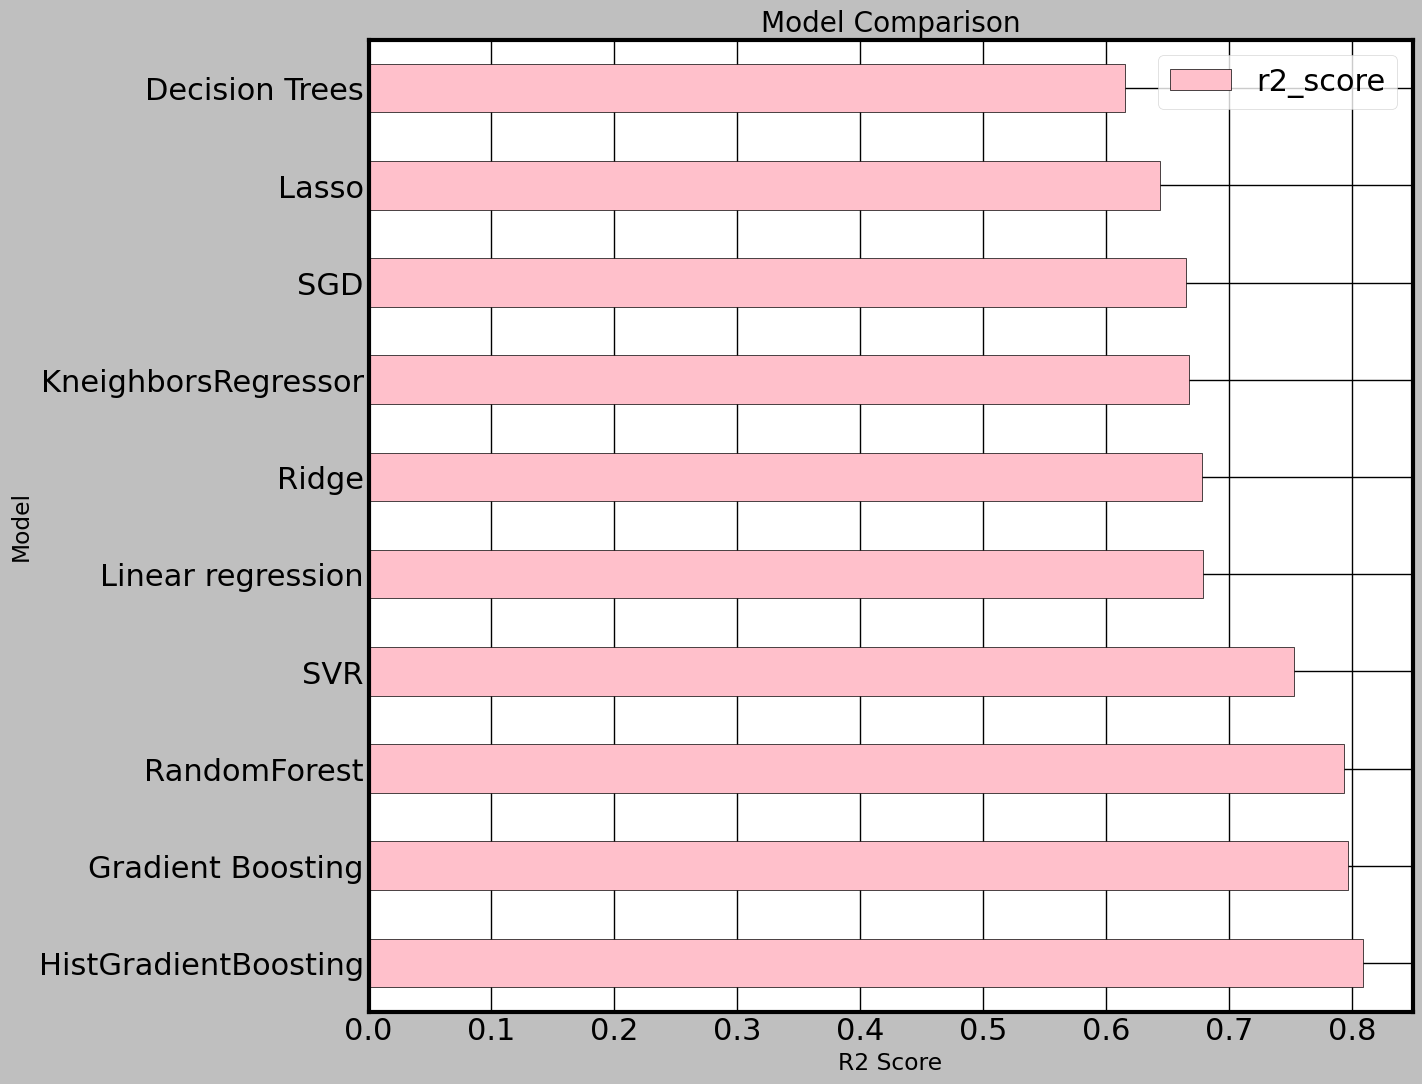

In [58]:
plt.style.use("grayscale")
df=pd.DataFrame({"model":["Linear regression","Ridge","Lasso","SGD","Decision Trees","RandomForest","SVR","KneighborsRegressor","Gradient Boosting","HistGradientBoosting"],
                 "r2_score":[lr_r2,rr_r2,lassor_r2,sgdr_r2,decisionr_r2,randomr_r2,svm_r2,kneighborr_r2,gbr_r2,hbgr_r2]})
df.sort_values(by="r2_score",ascending=False).plot(x="model",y="r2_score",kind="barh",color="pink",figsize=(12,12))
plt.xlabel("R2 Score")
plt.ylabel("Model")
plt.title("Model Comparison")
plt.show()

In [59]:
# Model Optimization(By using HyperParameter Tuning)
#alpha for ridge
alpha=[0.001,0.01,0.1,1,10]

#alpha for ridge
alpha=[0.001,0.1,1.0,10]

#loss for sgd
loss=['squared_error', 'huber']

#penalty type for
penalty=['l2', 'l1', 'elasticnet']

# alpha for sgd
alpha=[0.0001, 0.001, 0.01, 0.1]

#kernal for svr
kernel=['linear', 'rbf']

#C for svr
C=[0.1, 1, 10, 100]

#epsilon for svr
epsilon=[0.01, 0.1, 0.2]

#n_neighbors for nereastneighbors
n_neighbors=[3,5,7,11]

#weights for decisiontree
weights=['uniform', 'distance']

# max_depth for DecisionTreeRegressor
max_depth = [3, 5, 7, 10, None]

# min_samples_split for DecisionTreeRegressor
min_samples_split = [2, 5, 10]

# min_samples_leaf for DecisionTreeRegressor
min_samples_leaf = [1, 2, 4]


# n_estimators for RandomForestRegressor
n_estimators = [100, 200, 300]

# max_depth for RandomForestRegressor
max_depth = [10, 20, 30, None]

# max_features for RandomForestRegressor
max_features = ['sqrt', 1.0, 0.5]


# n_estimators for GradientBoostingRegressor
n_estimators = [100, 200]

# learning_rate for GradientBoostingRegressor
learning_rate = [0.01, 0.05, 0.1]

# max_depth for GradientBoostingRegressor
max_depth = [3, 5, 7]


# max_iter for HistGradientBoostingRegressor
max_iter = [100, 200, 300]

# learning_rate for HistGradientBoostingRegressor
learning_rate = [0.01, 0.05, 0.1]

# max_leaf_nodes for HistGradientBoostingRegressor
max_leaf_nodes = [15, 31, 63]

# min_samples_leaf for HistGradientBoostingRegressor
min_samples_leaf = [10, 20, 30]



In [60]:
from sklearn.model_selection import RandomizedSearchCV

In [61]:
# 1)Ridge Regression
hyperparametergrid={"alpha":[0.001,0.01,0.1,1,10,100]}
ridge=Ridge()
random=RandomizedSearchCV(estimator=ridge,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random.fit(x_train_scaled,y_train)
print("best params",random.best_params_)
print("best score",random.best_score_)




Fitting 5 folds for each of 6 candidates, totalling 30 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 6 is smaller than n_iter=10. Running 6 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params {'alpha': 0.1}
best score 0.661666230544134


In [62]:
#2) Lasso
hyperparametergrid={"alpha":[0.001,0.01,0.1,1,10]}
lasso=Lasso()
random=RandomizedSearchCV(estimator=lasso,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random.fit(x_train_scaled,y_train)
print("best params",random.best_params_)
print("best score",random.best_score_)



Fitting 5 folds for each of 5 candidates, totalling 25 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params {'alpha': 0.001}
best score 0.6617541560045108


In [63]:
hyperparametergrid={
    "loss":['squared_error', 'huber'],
    #penalty type for
    "penalty":['l2', 'l1', 'elasticnet'],
    # alpha for sgd
    "alpha":[0.0001, 0.001, 0.01, 0.1]
}
sgd=SGDRegressor()
random=RandomizedSearchCV(estimator=sgd,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random.fit(x_train_scaled,y_train)
print("best params",random.best_params_)
print("best score",random.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'penalty': 'l1', 'loss': 'squared_error', 'alpha': 0.001}
best score 0.6423814642721407


In [64]:
#4)decision tree
model=DecisionTreeRegressor()
hyperparametergrid={
# max_depth for DecisionTreeRegressor
'max_depth':[3, 5, 7, 10, None],

# min_samples_split for DecisionTreeRegressor
'min_samples_split':[2, 5, 10],

# min_samples_leaf for DecisionTreeRegressor
'min_samples_leaf':[1, 2, 4]}

random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 7}
best score 0.7514092634701226


In [65]:
model=RandomForestRegressor()
hyperparametergrid={# n_estimators for RandomForestRegressor
"n_estimators":[100, 200, 300],

# max_depth for RandomForestRegressor
"max_depth":[10, 20, 30, None],

#min_samples_leaf
"min_samples_leaf":[1, 2, 4],

#min_samples_split
"min_samples_split":[2,5,10],

# max_features for RandomForestRegressor
"max_features":['sqrt', 1.0, 0.5]
}
random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
best score 0.7967745594206184


In [66]:
# 6)SVR
model=SVR()
hyperparametergrid={
#kernal for svr
"kernel":['linear', 'rbf'],

#C for svr
"C":[0.1, 1, 10, 100],

#epsilon for svr
"epsilon":[0.01, 0.1, 0.2]}
random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)



Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'kernel': 'rbf', 'epsilon': 0.1, 'C': 100}
best score 0.7581061005589219


In [67]:
#7) KNR
model=KNeighborsRegressor()
hyperparametergrid={#n_neighbors for nereastneighbors
"n_neighbors":[3,5,7,11]}
random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)


Fitting 5 folds for each of 4 candidates, totalling 20 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=10. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


best params {'n_neighbors': 5}
best score 0.6542158452215284


In [68]:
#8) GRADIENTBOOSTING
model=GradientBoostingRegressor()
hyperparametergrid={ #n_estimators for GradientBoostingRegressor
"n_estimators":[100, 200,300,50],

# learning_rate for GradientBoostingRegressor
"learning_rate":[0.01, 0.05, 0.1,0.2],

# max_depth for GradientBoostingRegressor
"max_depth":[3, 5, 7,9,6],

"subsample":[0.6,0.8,1.0],

"min_samples_split":[2,5,10,15],

"criterion":["squared_error","friedman_mse"],

"max_features":['sqrt',"log2"]}
random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'subsample': 1.0, 'n_estimators': 100, 'min_samples_split': 10, 'max_features': 'log2', 'max_depth': 7, 'learning_rate': 0.1, 'criterion': 'friedman_mse'}
best score 0.7852669016819349


In [69]:
#9) hist gradient boosting
model=HistGradientBoostingRegressor()
hyperparametergrid={# max_iter for HistGradientBoostingRegressor
"max_iter":[100,150, 200,175, 250,300],

# learning_rate for HistGradientBoostingRegressor
"learning_rate":[0.01, 0.05, 0.1,0.06,0.04,0.03,1],

# max_leaf_nodes for HistGradientBoostingRegressor
"max_leaf_nodes":[15, 31,25,15,40, 63,70,75,40,50],

# min_samples_leaf for HistGradientBoostingRegressor
"min_samples_leaf":[5,10, 20, 30,40,127,150,130,100,60,50],

"max_depth":[None,3,7,8,6,11,4,5,10,1],

"l2_regularization":[0.01,0.1,1.0,2.0,3.0,0.5,0.2,0.05,10.0]
}
random_search=RandomizedSearchCV(estimator=model,param_distributions=hyperparametergrid,cv=5,n_jobs=-1,verbose=2)
random_search.fit(x_train_scaled,y_train)
print("best params",random_search.best_params_)
print("best score",random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
best params {'min_samples_leaf': 5, 'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': 4, 'learning_rate': 0.1, 'l2_regularization': 1.0}
best score 0.8077216613422198


In [70]:
### Training Hist gradient Boosting Again  with hyper parameters
model=HistGradientBoostingRegressor(learning_rate=0.05,max_iter=200,max_leaf_nodes=31,min_samples_leaf=20,max_depth=None,l2_regularization=10.0)
model.fit(x_train_scaled,y_train)
y_pred=model.predict(x_test_scaled)
print("MAE",MAE(y_test,y_pred))
print("R2",r2_score(y_test,y_pred))

MAE 8.880786306770789
R2 0.8120802508141266


In [73]:
### Again training with  new hyper parameters for gradient boosting
model = GradientBoostingRegressor(subsample=0.8, n_estimators=100, min_samples_split=15, max_depth=7, learning_rate=0.05)
model.fit(x_train_scaled, y_train)
y_pred = model.predict(x_test_scaled)
print("MAE",MAE(y_test,y_pred))
print("R2",r2_score(y_test,y_pred))

MAE 8.950200148534952
R2 0.8101955229249698


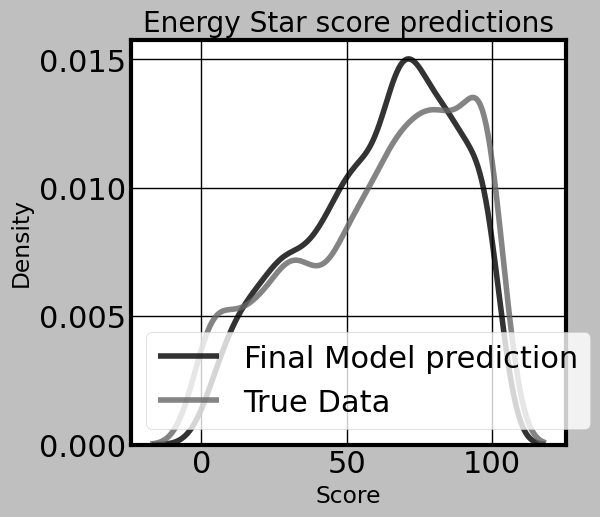

In [76]:
figsize(5,5)
sns.kdeplot(y_pred, label = "Final Model prediction", alpha = 0.8)
sns.kdeplot(y_test, label = "True Data", alpha = 0.8)
plt.xlabel("Score")
plt.ylabel("Density")
plt.title("Energy Star score predictions")
plt.legend()
plt.show()